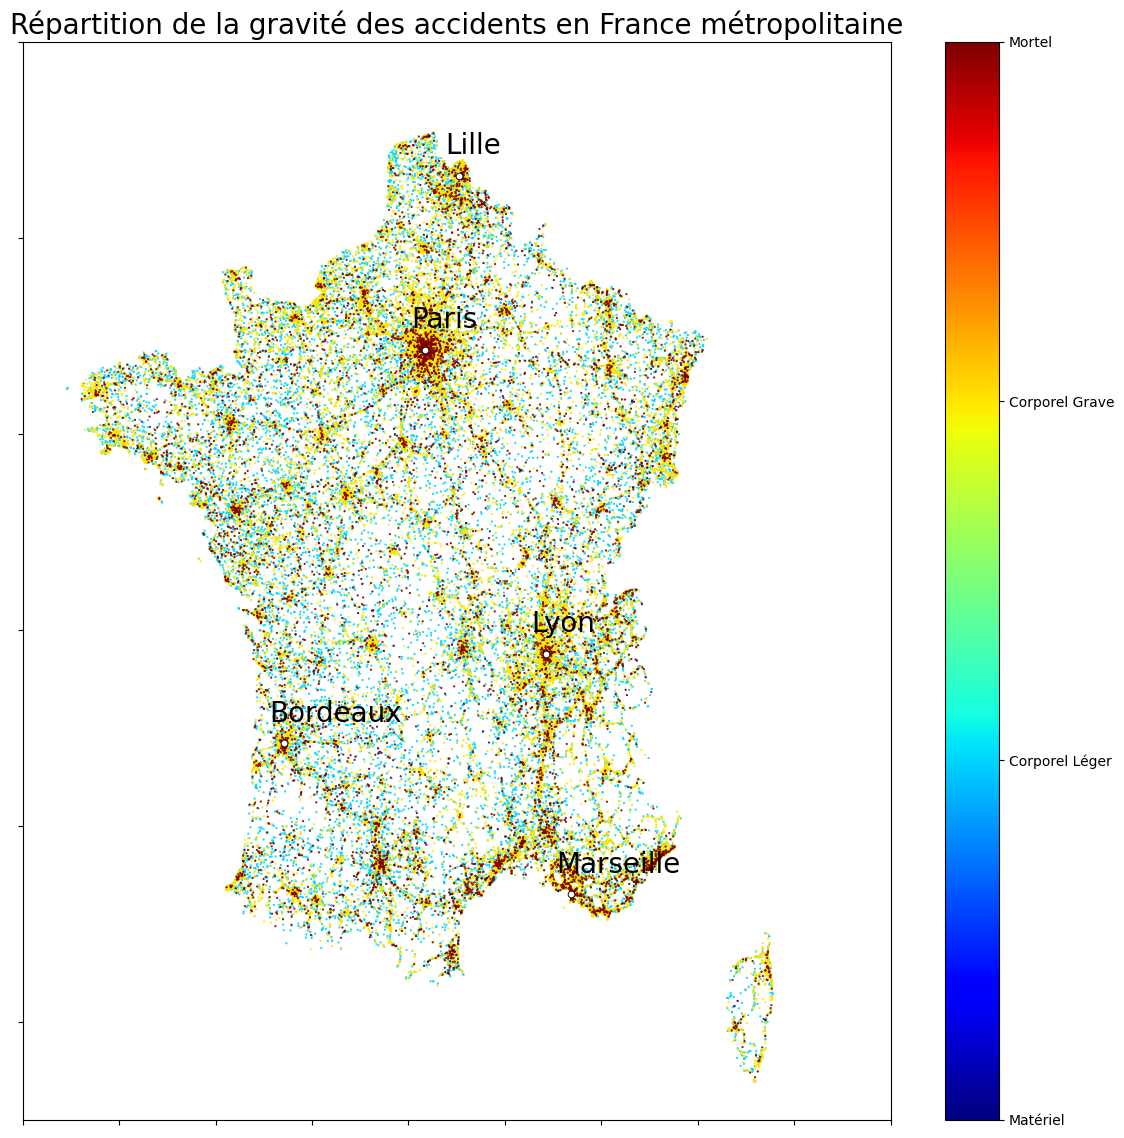

In [4]:
%config Completer.use_jedi = False
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv('000_df_RAW.csv', low_memory=False)




"transformation en float et extraction des données non aberrantes"
def safe_float_conversion(value):
    try:
        # Essaye de convertir la valeur en nombre flottant
        return float(value)
    except ValueError:
        # Si la conversion échoue, renvoie NaN
        return float('nan')

lat=df['lat'].str.replace(',', '.').apply(safe_float_conversion)
long=df['long'].str.replace(',', '.').apply(safe_float_conversion)

long = long.where(long <= 180)
df['long'] = long.where(long >= -180)
lat = lat.where(lat <= 180)
df['lat'] = lat.where(lat >= -180)



"travail sur la variable grav"
df['grav']=df['grav'].replace({1:0,2:3,3:1,4:2})
df_sorted = df.sort_values(by='grav')
df_sorted=df_sorted.drop_duplicates(subset='Num_Acc',keep='last')



#création de la figure
fig=plt.figure(figsize=[14,14])
plt.scatter(df_sorted['long'],df_sorted['lat'],s=0.3,c=df_sorted.grav,cmap='jet') 
plt.xlim(-6, 12)  
plt.ylim(41, 52)
colorbar=plt.colorbar(ticks=[0,1,2,3])
colorbar.ax.set_yticklabels(['Matériel', 'Corporel Léger', 'Corporel Grave', 'Mortel'])

villes = pd.DataFrame({
    'Ville': ['Paris', 'Marseille', 'Lyon', 'Bordeaux','Lille'],
    'Latitude': [48.8566, 43.2964, 45.75,  44.8378,50.6292],
    'Longitude': [2.3522, 5.3699, 4.85, -0.5792,3.0573]})


decalage=0.15
taille=20
for index, row in villes.iterrows():
    plt.text(row['Longitude']-2*decalage, row['Latitude']+1.5*decalage, row['Ville'], fontsize=taille)
    plt.scatter(row['Longitude'], row['Latitude'],s=taille,c='black')
    plt.scatter(row['Longitude'], row['Latitude'],s=taille-taille/2,c='white')

plt.title("Répartition de la gravité des accidents en France métropolitaine",fontsize=taille)
plt.xticks(visible=False)
plt.yticks(visible=False);